In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

# Set random seed for reproducibility
np.random.seed(42)

In [2]:
def generate_maze(width=20, height=20, obstacle_ratio=0.3):
    """Generates a 2D grid representing a maze with random obstacles."""
    maze = np.random.choice([0, 1], size=(height, width), p=[1 - obstacle_ratio, obstacle_ratio])
    # Ensure start and goal are always free paths
    maze[0, 0] = 0
    maze[height - 1, width - 1] = 0
    return maze

def get_neighbors(node, maze):
    """
    Implicitly computes edges on demand.
    Returns valid orthogonal neighbors (Up, Down, Left, Right) within maze boundaries
    that are not blocked by an obstacle (value is 0).
    """
    y, x = node
    height, width = maze.shape
    neighbors = []
    # Movement vectors: Up, Down, Left, Right
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for dy, dx in directions:
        ny, nx = y + dy, x + dx
        if 0 <= ny < height and 0 <= nx < width:
            if maze[ny, nx] == 0:
                neighbors.append((ny, nx))
    return neighbors

In [3]:
def run_search(maze, start=(0, 0), goal=None, is_dfs=False):
    """
    Performs BFS or DFS search depending on the `is_dfs` flag.
    Returns the parent dictionary, explored order list, and the list of cells expanded.
    """
    if goal is None:
        goal = (maze.shape[0] - 1, maze.shape[1] - 1)

    frontier = deque([start])
    explored = set()
    # Set to track elements already in frontier to avoid redundant expansions
    frontier_set = {start}
    parent = {start: None}
    expanded_order = []

    while frontier:
        # The key difference: DFS uses pop() (LIFO), BFS uses popleft() (FIFO)
        node = frontier.pop() if is_dfs else frontier.popleft()

        if node in explored:
            continue

        explored.add(node)
        expanded_order.append(node)

        if node == goal:
            break

        for neighbor in get_neighbors(node, maze):
            if neighbor not in explored and neighbor not in frontier_set:
                parent[neighbor] = node
                frontier.append(neighbor)
                frontier_set.add(neighbor)

    return parent, expanded_order

def reconstruct_path(parent, start, goal):
    """Reconstructs the path from goal to start using the parent dictionary."""
    if goal not in parent:
        return [] # Goal unreachable
    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = parent[current]
    return path[::-1] # Reverse to get path from start to goal

Let's generate a maze and test our implementation, comparing the path lengths and nodes expanded by both algorithms.

In [4]:
maze = generate_maze(width=20, height=20, obstacle_ratio=0.25)
start = (0, 0)
goal = (19, 19)

# Run BFS
parent_bfs, expanded_bfs = run_search(maze, start, goal, is_dfs=False)
path_bfs = reconstruct_path(parent_bfs, start, goal)

# Run DFS
parent_dfs, expanded_dfs = run_search(maze, start, goal, is_dfs=True)
path_dfs = reconstruct_path(parent_dfs, start, goal)

print(f"BFS Nodes Expanded: {len(expanded_bfs)} | Path Length: {len(path_bfs)}")
print(f"DFS Nodes Expanded: {len(expanded_dfs)} | Path Length: {len(path_dfs)}")

BFS Nodes Expanded: 295 | Path Length: 39
DFS Nodes Expanded: 208 | Path Length: 49


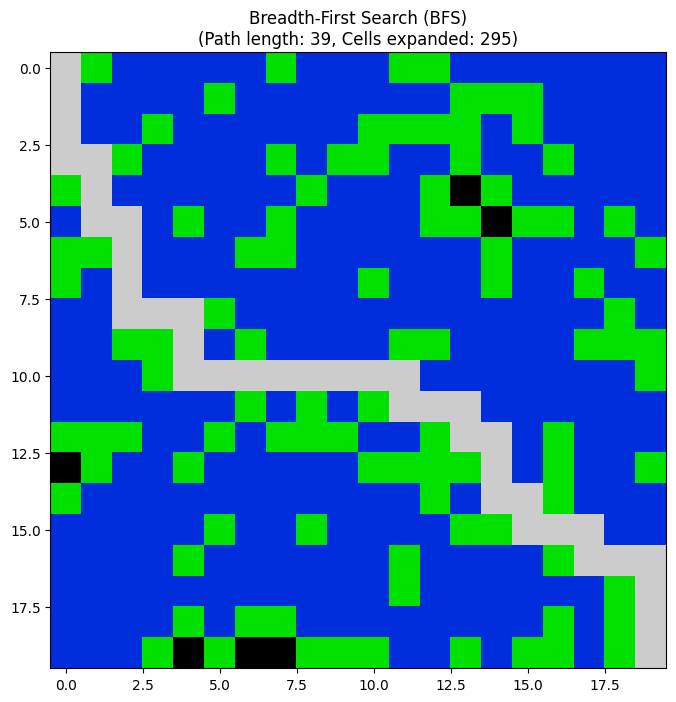

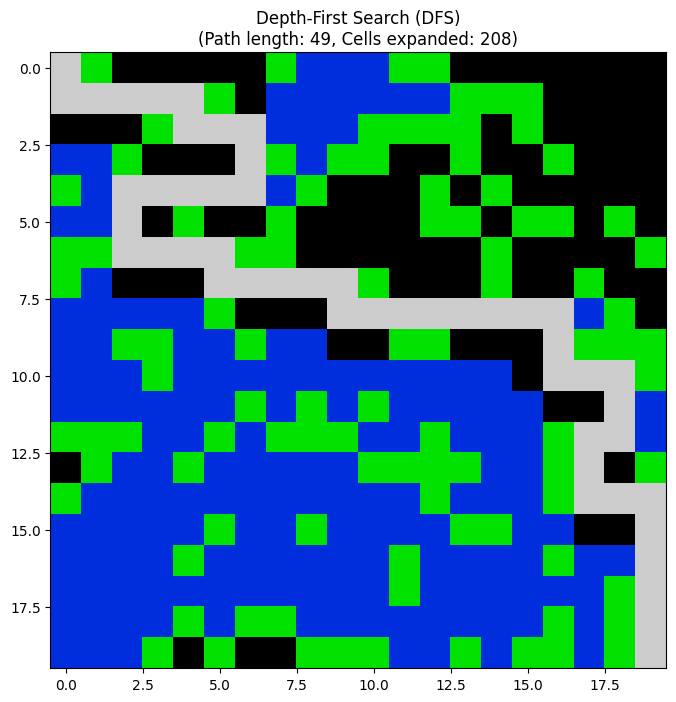

In [5]:
def plot_search_results(maze, path, expanded, title):
    plt.figure(figsize=(8, 8))
    # Base Grid (obstacles as dark, open space as white)
    grid = np.zeros_like(maze, dtype=float)
    grid[maze == 1] = 0.5 # Obstacles

    # Mark all expanded nodes in light blue/cyan
    for y, x in expanded:
        grid[y, x] = 0.2

    # Mark path nodes in yellow
    for y, x in path:
        grid[y, x] = 0.9

    plt.imshow(grid, cmap='nipy_spectral', origin='upper')
    plt.title(f"{title}\n(Path length: {len(path)}, Cells expanded: {len(expanded)})")
    plt.grid(False)
    plt.show()

# Plotting side by side
plot_search_results(maze, path_bfs, expanded_bfs, "Breadth-First Search (BFS)")
plot_search_results(maze, path_dfs, expanded_dfs, "Depth-First Search (DFS)")